## Pegasus Evaluation: Load

Section B.4. Setup, methods and metrics: `2_B1_base_case.ipynb`; parameters: `pegasus/evaluation_setup.py`.
B.4 runs on `data_source`.

In [1]:
# Data source of B.4:
# - "real": the chain of B.1 measured again under other loads and arrival patterns (statics/results_milos_v2/b4/, pegasus/real_data.py)
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table, time_table
b4_names = sweep_competitors + ["Oracle"]   # the methods of the tables of B.4
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/cache/evaluation/ (written by the first
# notebook that needs it), or computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {N_TRAIN if data_source == 'real' else n_train} training runs per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 loaded from cache\evaluation\b1_real+b1+b1u-max4_cbb2e2fd98b558ff.joblib
real data, 10 seeds: chain detector -> transformer -> compressor, per seed 50 training runs per service and 149 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 65/s)


### B.4 Varying Load and Arrival Pattern

The chain of B.1 under other arrivals at its first service. Training and methods as in B.1, without DNN Sum and Pegasus
SNC; only the arrivals and the ground truth change.

- **Inputs (real data):** every method trains on `N_TRAIN` benchmark runs per service with one to four workers, and
  every model receives the quality knobs, the number of workers $c$ and $\log_{10}$ of the arrival rate $\lambda$
  (items/s) (`same_information_methods` in `pegasus/evaluation.py`). Pegasus uses the arrival process in its queueing
  part, GP Queue the rate and $C^2$; GP Sum ignores the arrivals.
- **Held-out runs (real data):** the chain detector → transformer → compressor, measured again under every setting with
  the same configurations (`statics/results_milos_v2/b4/`, two measurements). A run is held out if no service has more
  than `b4_max_workers` workers and the testbed sustained it at every setting of the sweep (`b4_held_out` in
  `pegasus/real_data.py`); the testbed marks a run invalid when the queue of its busiest service keeps growing. The
  ground truth is the measured latency quantile of the run.
- **Synthetic data:** the chain and held-out configurations of B.1, with simulated arrivals and ground truth.
- **Infinite bounds:** a method gives an infinite bound when its model expects a service to be overloaded (utilization
  ≥ 1). With real data, coverage and tightness are computed on the runs with a finite bound only, and a table cell ends
  in "(∞ x%)", the share of runs without one (`finite_bound_statistics` in `pegasus/figures.py`). Whether the infinite
  bounds fall on the runs that really overloaded is scored in *B.4a Overload Detection*.

#### B.4a Load

Poisson arrivals at every load in `loads`. Real data: the load is the utilization $u$ of the busiest service (the share
of time that its workers are busy), which the testbed targets by setting the arrival rate from a short probe; the table
gives the measured utilization. At $u = 1$ many runs overload, so $u = 1$ is evaluated on its own sustained runs
(`utilization_one.py`) and drawn as a separate point at the right of the figure. Synthetic data: the load is the arrival
rate (items/s).

Figure `figures/tsc/experimental-results/b4a_load_<data source>`: per method, the tightness (bound ÷ measured quantile,
log scale), median over the seeds with a band from the smallest to the largest seed; a filled marker where the coverage
reaches the confidence level under every seed. The label at $u = 1$ is the share of the overloaded runs at $u = 1$
for which Pegasus gives an infinite bound (*B.4a Overload Detection*).


In [2]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    # B.4a: the chain of B.1 under Poisson arrivals of different load (`loads`: arrival rate with synthetic data, utilization of the busiest service with real data)
    base_load = workload["rate"] if data_source == "synthetic" else base_utilization
    assert base_load in loads, "the load of B.1 is not one of the settings"
    # Real data: every method on the same information as in B.1 (same_information_methods in pegasus/evaluation.py).
    # Synthetic data: the models of B.1, with every method that B.4 computes there.
    leave_out = only_base_case + (PROPOSED_SNC,)

    def compute():
        load_methods, load_truth = {}, {}   # (load, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
        # held-out configurations of every seed: synthetic, those of B.1; real, those of the first load, which every load must repeat
        held_out_x = {s: bases[s].x_test for s in seeds} if data_source == "synthetic" else {}
        with warnings.catch_warnings():
            # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for load in loads:
                for s in seeds:
                    if data_source == "real":   # trained on the worker benchmarks, workers and rate as inputs of every model
                        data = b4_data(s, "load", load, training_campaign=WORKER_TRAINING, n_train=N_TRAIN)
                        load_methods[(load, s)] = same_information_methods(data, seed + s, alpha, confidence, n_calibration)
                    else:
                        data = b4_data(s, "load", load, n_train=n_train)
                        # the execution times do not depend on the arrivals, so every load uses the models of B.1
                        assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.path), "the training data differs from that of B.1"
                        load_methods[(load, s)], _ = compare_methods(data, base_models[s], data.x_train, data.monitored_latencies, alpha, confidence,
                                                                     n_calibration, model_seed=seed + s, leave_out=leave_out, x_train_load=data.x_train_load)
                    assert same_configurations(data.x_test, held_out_x.setdefault(s, data.x_test)), "the held-out configurations differ between the loads"
                    load_truth[(load, s)] = (data.measured, data.measured_low)
        return dict(load_methods=load_methods, load_truth=load_truth)

    globals().update(cached("b4a_load", data_source, compute, inputs=dict(loads=loads, load_option=load_option,
                                                                         b4_max_workers=globals().get("b4_max_workers"))))
    # utilization of the busiest service per held-out configuration: synthetic, the true one, the seeds one after the other;
    # real, the measured one of every held-out run (the same runs under every seed)
    load_utilization = {load: np.concatenate([busiest_utilization(base.path, bases[s].x_test, load, service_seed=s) for s in seeds])
                        if data_source == "synthetic" else b4_utilization("load", load, loads, b4_max_workers) for load in loads}
    if data_source == "synthetic":   # a measured run can exceed its utilization briefly; the testbed left out the runs whose queue kept growing
        assert max(utilization.max() for utilization in load_utilization.values()) < 1, "a service is overloaded at a held-out configuration"
    load_held_out = {load: len(load_truth[(load, seeds[0])][0]) for load in loads}   # held-out configurations per seed
    assert all(len(load_utilization[load]) == load_held_out[load] * (len(seeds) if data_source == "synthetic" else 1) for load in loads)
    print(f"{len(load_methods)} combinations of load and seed evaluated.")

b4a_load: results loaded from cache\evaluation\b4a_load_real+b1+b1u-max4_bb11d8c847e2e5f3.joblib
60 combinations of load and seed evaluated.


measured utilization of the busiest service, median over the held-out runs: 0.10 at u = 0.1, 0.24 at u = 0.25, 0.39 at u = 0.4, 0.49 at u = 0.5, 0.68 at u = 0.7, 0.88 at u = 0.9
B.4a load, real data: detector → transformer → compressor, 85 held-out runs (at most 4 workers per service, valid at every load),
poisson arrivals, 10 seeds


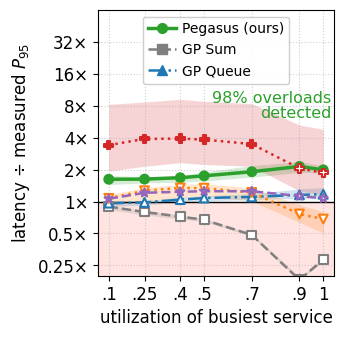

In [3]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    # name -> coverage, tightness, holds, computed; real data: on the runs with a finite bound (B.4 markdown)
    from pegasus.figures import finite_bound_statistics
    statistics_of = finite_bound_statistics if data_source == "real" else sweep_statistics
    load_statistics = statistics_of(load_methods, load_truth, loads, seeds, confidence)
    # one short label and one row of ticks, because B.4a and B.4b sit side by side in the width of one figure; the utilization
    # of the busiest service at every rate is printed instead of drawn
    load_axis = "arrival rate λ (items/s)" if data_source == "synthetic" else "utilization of busiest service"
    if data_source == "synthetic":
        print("utilization of the busiest service, median over the held-out configurations of all seeds: "
              + ", ".join(f"{np.median(load_utilization[load]):.2f} at {load:g}/s" for load in loads))
        held_out_text = f"{load_held_out[loads[0]]} held-out configurations per seed"
    else:
        print("measured utilization of the busiest service, median over the held-out runs: "
              + ", ".join(f"{np.median(load_utilization[load]):.2f} at u = {load:g}" for load in loads))
        held_out_text = f"{load_held_out[loads[0]]} held-out runs (at most {b4_max_workers} workers per service, valid at every load)"
    # u = 1 on its own sustained runs (utilization_one.py), drawn beside the sweep
    marked = None
    if data_source == "real":
        from utilization_one import utilization_one
        one = utilization_one()
        # the label at u = 1: the share of the overloaded runs at u = 1 for which Pegasus gives an infinite bound (overload_detection.py)
        from overload_detection import overload_detection
        at_one = overload_detection()[1.0]
        detected = np.median([np.mean(~np.isfinite(at_one["methods"][s][PROPOSED][1][at_one["overloaded"]])) for s in seeds])
        marked = dict(x=1.0, tick="1", statistics=finite_bound_statistics(one["methods"], one["truth"], [1.0], seeds, confidence), methods=one["methods"],
                      label=f"{detected:.0%} overloads\ndetected")
    tightness_sweep_figure(loads, load_statistics, load_axis,
                           f"B.4a load, {data_source} data: {' → '.join(base.path)}, {held_out_text},\n"
                           f"{workload['process']} arrivals, {len(seeds)} seeds", p_label,
                           tick_labels=[f"{load:g}".removeprefix("0") if 0 < load < 1 else f"{load:g}" for load in loads],   # .25 instead of 0.25, as in B.4b
                           log_x=False, name=f"b4a_load_{data_source}", half="left", marked=marked)

In [4]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    table = sweep_table(loads, load_statistics, b4_names, load_label, load_truth, seeds, load_methods)
    table.loc["busiest utilization (median / max)"] = [f"{np.median(load_utilization[load]):.2f} / {load_utilization[load].max():.2f}" for load in loads]
    table.loc["held-out configurations per seed"] = [load_held_out[load] for load in loads]
    print(f"{data_source} data, tightness (median over the seeds{', on the runs with a finite bound' if data_source == 'real' else ''}; ● holds, ○ does not):")
    display(table)

real data, tightness (median over the seeds, on the runs with a finite bound; ● holds, ○ does not):


,u = 0.1,u = 0.25,u = 0.4,u = 0.5,u = 0.7,u = 0.9
Pegasus (ours),1.62× ●,1.62× ●,1.67× ●,1.74× ●,1.91× ●,2.14× ● (∞ 38%)
GP Sum,0.89× ○,0.80× ○,0.72× ○,0.67× ○,0.48× ○,0.18× ○
GP Queue,0.96× ○,0.98× ○,1.04× ○,1.08× ○,1.10× ○,1.16× ○ (∞ 4%)
Quantile Union,1.07× ○,1.26× ○,1.34× ○,1.34× ○,1.22× ○,0.76× ○
Conformal,3.40× ●,3.89× ●,3.91× ●,3.83× ●,3.48× ●,2.05× ○
Oracle,1.06× ●,1.21× ●,1.24× ●,1.25× ●,1.25× ●,1.13× ○
measured (s),0.0921,0.0999,0.108,0.12,0.188,0.547
busiest utilization (median / max),0.10 / 0.14,0.24 / 0.28,0.39 / 0.44,0.49 / 0.56,0.68 / 0.80,0.88 / 1.02
held-out configurations per seed,85,85,85,85,85,85


#### B.4a Overload Detection

The sweep holds out only sustained runs, so there an infinite bound is always a false alarm. Here every run at u = 0.9
and u = 1 is scored, including the runs that the testbed flagged `detector:overloaded`, whose ground truth is ∞
(`overload_detection.py`; below u = 0.9 no run overloaded). Methods and inputs as in the sweep; no Oracle, because it
needs the steady-state latencies of the run.

Per method, every run falls in one cell of predicted (∞ or finite) × measured (overloaded or sustained): a **correct
alarm**, a **false alarm** (a guarantee withheld that the system could have kept), a **missed overload** (a finite bound
for a latency that grows without limit), or finite and sustained, the runs on which coverage and tightness are computed.
Counts are runs, median over the seeds.


In [5]:
if data_source != "real":
    print("B.4a overload detection: real data only (the synthetic sweep has no overloaded run)")
else:
    # every run at u = 0.9 and u = 1, the overloaded ones with an infinite ground truth (overload_detection.py, own cache)
    from overload_detection import overload_detection, detection_table
    detection = overload_detection()
    detection_names = [name for name in b4_names if name != "Oracle"]
    print(f"{data_source} data, {len(seeds)} seeds: runs per cell (median over the seeds), coverage and tightness on the finite and "
          f"sustained runs (median over the seeds; ● coverage ≥ {confidence:.0%} under every seed)")
    display(detection_table(detection, detection_names, confidence))

    # the numbers of the conclusion, for Pegasus at every load
    lines = []
    for load, r in detection.items():
        infinite = np.array([~np.isfinite(r["methods"][s][PROPOSED][1]) for s in seeds])
        overloaded = r["overloaded"]
        median = lambda mask: f"{np.median(mask.sum(axis=1)):g}"   # a median over an even number of seeds can end in .5
        lines.append(f"- **u = {load:g}:** the testbed overloaded {overloaded.sum()} of {len(overloaded)} runs. {PROPOSED} gave an "
                     f"infinite bound for {median(infinite & overloaded)} of them and a finite bound for {median(~infinite & overloaded)} "
                     f"(missed overloads); it also gave an infinite bound for {median(infinite & ~overloaded)} of the "
                     f"{(~overloaded).sum()} sustained runs (false alarms).")
    display(Markdown("\n".join(lines)))


real data, 10 seeds: runs per cell (median over the seeds), coverage and tightness on the finite and sustained runs (median over the seeds; ● coverage ≥ 95% under every seed)


u = 0.9     u = 1
runs           overloaded / all                         14 / 99  44 / 100
Pegasus (ours) ∞ predicted, overloaded (correct alarm)       14        43
               ∞ predicted, sustained (false alarm)          32      25.5
               finite, overloaded (missed overload)           0         1
               finite, sustained                             53      30.5
               coverage, finite and sustained            100% ●    100% ●
               tightness, finite and sustained            2.14×     1.99×
GP Sum         ∞ predicted, overloaded (correct alarm)        0         0
               ∞ predicted, sustained (false alarm)           0         0
               finite, overloaded (missed overload)          14        44
               finite, sustained                             85        56
               coverage, finite and sustained              0% ○      0% ○
               tightness, finite and sustained            0.18×     0.28×
GP Queue       ∞ predicted, overloaded (correct alarm)     10.5        37
               ∞ predicted, sustained (false alarm)         3.5        13
               finite, overloaded (missed overload)         3.5         7
               finite, sustained                           81.5        43
               coverage, finite and sustained             85% ○     84% ○
               tightness, finite and sustained            1.16×     1.17×
Quantile Union ∞ predicted, overloaded (correct alarm)        0         0
               ∞ predicted, sustained (false alarm)           0         0
               finite, overloaded (missed overload)          14        44
               finite, sustained                             85        56
               coverage, finite and sustained             46% ○     40% ○
               tightness, finite and sustained            0.76×     0.68×
Conformal      ∞ predicted, overloaded (correct alarm)        0         0
               ∞ predicted, sustained (false alarm)           0         0
               finite, overloaded (missed overload)          14        44
               finite, sustained                             85        56
               coverage, finite and sustained             82% ○     74% ○
               tightness, finite and sustained            2.05×     1.86×

- **u = 0.9:** the testbed overloaded 14 of 99 runs. Pegasus (ours) gave an infinite bound for 14 of them and a finite bound for 0 (missed overloads); it also gave an infinite bound for 32 of the 85 sustained runs (false alarms).
- **u = 1:** the testbed overloaded 44 of 100 runs. Pegasus (ours) gave an infinite bound for 43 of them and a finite bound for 1 (missed overloads); it also gave an infinite bound for 25.5 of the 56 sustained runs (false alarms).

#### B.4b Arrival Pattern

Renewal arrivals with independent, gamma-distributed gaps, whose squared coefficient of variation $C^2$ = variance ÷
mean² of a gap takes the values in `arrival_cv2s`: $C^2 = 1$ is the Poisson process of B.1, a smaller $C^2$ spaces the
arrivals more evenly, a larger one makes them burstier, and $C^2 = 0$ (real data only) is strictly periodic
(`measured_arrivals` in `pegasus/real_data.py`). Real data: the busiest service at utilization 0.5, as in B.1; a setting
that one measurement did not complete holds out the runs of the other one only (the table gives the count), and the
figure spaces the settings evenly because $C^2 = 0$ has no place on a log scale. Synthetic data: at the arrival rate of B.1.

Figure: `figures/tsc/experimental-results/b4b_arrivals_<data source>`.


In [6]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    # B.4b: the chain of B.1 under arrivals of different variability (`arrival_cv2s`) at the load of B.1

    # real data: every method on the same information as in B.1 (same_information_methods in pegasus/evaluation.py);
    # synthetic data: the models of B.1, with every method that B.4 computes there
    leave_out = only_base_case + (PROPOSED_SNC,)

    def compute():
        arrival_methods, arrival_truth = {}, {}   # (cv2, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
        with warnings.catch_warnings():
            # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for cv2 in arrival_cv2s:
                for s in seeds:
                    if data_source == "real":   # trained on the worker benchmarks, workers and rate as inputs of every model
                        data = b4_data(s, "arrivals", cv2, training_campaign=WORKER_TRAINING, n_train=N_TRAIN)
                        arrival_methods[(cv2, s)] = same_information_methods(data, seed + s, alpha, confidence, n_calibration)
                    else:
                        data = b4_data(s, "arrivals", cv2)
                        assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
                        assert np.array_equal(data.workload["rate"], bases[s].workload["rate"]), "the arrival rates differ from those of B.1"
                        # the execution times do not depend on the arrivals, so the per-service models of B.1 are the models of every setting
                        assert same_configurations(data.x_train, bases[s].x_train), "the training configurations differ from those of B.1"
                        assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.path), "the training data differs from that of B.1"
                        arrival_methods[(cv2, s)], _ = compare_methods(data, base_models[s], data.x_train, data.monitored_latencies, alpha, confidence,
                                                                       n_calibration, model_seed=seed + s, leave_out=leave_out, x_train_load=data.x_train_load)
                    arrival_truth[(cv2, s)] = (data.measured, data.measured_low)
        return dict(arrival_methods=arrival_methods, arrival_truth=arrival_truth, gamma_arrivals=arrival_text(data.workload))

    globals().update(cached("b4b_arrivals", data_source, compute, inputs=dict(arrival_cv2s=arrival_cv2s, b4_max_workers=globals().get("b4_max_workers"))))
    arrival_held_out = {cv2: len(arrival_truth[(cv2, seeds[0])][0]) for cv2 in arrival_cv2s}   # held-out configurations per seed
    print(f"{len(arrival_methods)} combinations of arrival variability and seed evaluated.")

b4b_arrivals: results loaded from cache\evaluation\b4b_arrivals_real+b1+b1u-max4_4d7bebb33c597ef0.joblib
90 combinations of arrival variability and seed evaluated.


B.4b arrival variability, real data: detector → transformer → compressor, 50 to 100 held-out runs per setting (at most 4 workers per service),
renewal arrivals with gamma gaps at utilization 0.5 of the busiest service, 10 seeds
legend_inside: the legend hides 6 points or bands at its best location (upper right)


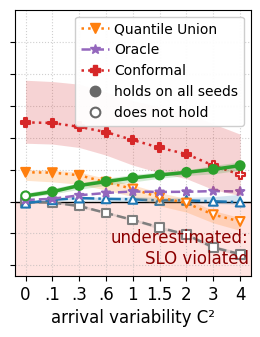

In [7]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    arrival_statistics = sweep_statistics(arrival_methods, arrival_truth, arrival_cv2s, seeds, confidence)   # name -> coverage, tightness, holds, computed
    if data_source == "synthetic":
        arrival_positions, arrival_axis, arrival_log_x = arrival_cv2s, "arrival variability C² (log scale)", True
        arrival_ticks = [f"{cv2:g}" for cv2 in arrival_cv2s]
        arrival_text_title = f"{arrival_held_out[arrival_cv2s[0]]} held-out configurations per seed,\n{gamma_arrivals}"
    else:   # C² = 0 has no place on a log scale: the settings evenly spaced, each labeled with its C²
        arrival_positions, arrival_axis, arrival_log_x = list(range(len(arrival_cv2s))), "arrival variability C²", False
        # without the leading zero (.1 instead of 0.1), so that the nine ticks fit the half-width figure
        arrival_ticks = [f"{cv2:g}".removeprefix("0") if 0 < cv2 < 1 else f"{cv2:g}" for cv2 in arrival_cv2s]
        counts = sorted(set(arrival_held_out.values()))
        arrival_text_title = (f"{' to '.join(map(str, [counts[0], counts[-1]] if len(counts) > 1 else counts))} held-out runs per setting "
                              f"(at most {b4_max_workers} workers per service),\nrenewal arrivals with gamma gaps at utilization {base_utilization:g} "
                              f"of the busiest service")
    tightness_sweep_figure(arrival_positions, arrival_statistics, arrival_axis,
                           f"B.4b arrival variability, {data_source} data: {' → '.join(base.path)}, {arrival_text_title}, {len(seeds)} seeds", p_label,
                           tick_labels=arrival_ticks, log_x=arrival_log_x, name=f"b4b_arrivals_{data_source}", half="right",
                           front=("Conformal", PROPOSED))   # Conformal in front of the other methods where they overlap, Pegasus in front of Conformal

In [8]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    print(f"{data_source} data, {gamma_arrivals if data_source == 'synthetic' else 'renewal arrivals'}, tightness (median over the seeds; ● holds, ○ does not):")
    table = sweep_table(arrival_cv2s, arrival_statistics, b4_names, lambda cv2: f"C² = {cv2:g}", arrival_truth, seeds)
    for name in [name for name in (PROPOSED,) if name in arrival_statistics]:
        table.loc[f"{name}: finite share"] = [f"{finite_share(arrival_methods, name, cv2, seeds):.0%}" for cv2 in arrival_cv2s]
    table.loc["held-out configurations per seed"] = [arrival_held_out[cv2] for cv2 in arrival_cv2s]
    display(table)

real data, renewal arrivals, tightness (median over the seeds; ● holds, ○ does not):


,C² = 0,C² = 0.1,C² = 0.3,C² = 0.6,C² = 1,C² = 1.5,C² = 2,C² = 3,C² = 4
Pegasus (ours),1.13× ○,1.24× ●,1.41× ●,1.54× ●,1.67× ●,1.78× ●,1.88× ●,2.01× ●,2.18× ●
GP Sum,0.99× ○,0.98× ○,0.91× ○,0.78× ○,0.67× ○,0.57× ○,0.49× ○,0.37× ○,0.32× ○
GP Queue,0.96× ○,1.04× ○,1.08× ○,1.06× ○,1.05× ○,1.02× ○,1.02× ○,1.00× ○,0.99× ○
Quantile Union,1.88× ●,1.87× ●,1.77× ●,1.52× ○,1.31× ○,1.09× ○,0.97× ○,0.75× ○,0.65× ○
Conformal,5.56× ●,5.49× ●,5.05× ●,4.50× ●,3.80× ●,3.21× ●,2.80× ●,2.18× ○,1.79× ○
Oracle,1.03× ●,1.06× ●,1.14× ●,1.20× ●,1.24× ●,1.23× ●,1.24× ●,1.25× ●,1.24× ●
measured (s),0.0955,0.0933,0.108,0.124,0.156,0.17,0.21,0.287,0.305
Pegasus (ours): finite share,100%,100%,100%,100%,100%,100%,100%,100%,100%
held-out configurations per seed,100,100,100,100,100,100,100,100,50
